In [1]:
%run ./methods.ipynb

loaded 920 rows, kept 740 after filtering
all the data checks look good


all 12 method checks look good


In [2]:
import matplotlib.pyplot as plt
from IPython.display import Image, display

SWITZERLAND = 2
HOSP = ["Cleveland", "Hungary", "Switzerland", "VA Long Beach"]
OUT = ROOT / CONFIG["output_dir"]

In [3]:
# turning the saved csvs into summaries
def privacy_label(df):
    return pd.Series(np.where(df["mode"] == "clip_only", "clip_only",
                              np.where(df["epsilon_target"].isna(), "nonprivate",
                                       "eps=" + df["epsilon_target"].fillna(0).map(lambda e: f"{e:g}"))), index=df.index)


def per_run(runs):
    def agg(d):
        no_ch = d[d.hospital_id != SWITZERLAND]
        return pd.Series({
            "macro_balanced_accuracy": d.balanced_accuracy.mean(),
            "worst_balanced_accuracy": d.balanced_accuracy.min(),
            "worst_hospital": d.loc[d.balanced_accuracy.idxmin(), "hospital_name"],
            "worst_balanced_accuracy_excl_switzerland": no_ch.balanced_accuracy.min(),
            "macro_balanced_accuracy_excl_switzerland": no_ch.balanced_accuracy.mean(),
            "macro_accuracy": d.accuracy.mean(), "worst_accuracy": d.accuracy.min(), "macro_auroc": d.auroc.mean(),
            "pooled_test_accuracy": (d.accuracy * d.n_test).sum() / d.n_test.sum(),
            "elapsed_seconds": d.elapsed_seconds.iloc[0],
            "patient_grad_evals": d.patient_grad_evals.sum() if d.name[3] != "pooled" else d.patient_grad_evals.iloc[0]})
    keys = ["run_id", "setting", "group", "method", "mode", "epsilon_target", "lambda", "weighting", "chol_policy",
            "train_fraction_site", "training_repetition"]
    out = runs.groupby(keys, dropna=False).apply(agg, include_groups=False).reset_index()
    out["privacy"] = privacy_label(out)
    return out


def summarize(pr):
    metrics = ["macro_balanced_accuracy", "worst_balanced_accuracy", "worst_balanced_accuracy_excl_switzerland",
               "macro_balanced_accuracy_excl_switzerland", "macro_accuracy", "worst_accuracy", "macro_auroc",
               "pooled_test_accuracy", "elapsed_seconds", "patient_grad_evals"]
    g = pr.groupby(["setting", "group", "method", "privacy", "lambda", "weighting", "chol_policy", "train_fraction_site"], dropna=False)
    s = g[metrics].agg(["mean", "std"])
    s.columns = [f"{a}_{b}" for a, b in s.columns]
    s["n_repetitions"] = g.size()
    s["worst_hospital_mode"] = g["worst_hospital"].agg(lambda x: x.value_counts().index[0])
    return s.reset_index()


def by_hospital(runs):
    runs = runs.assign(privacy=privacy_label(runs))
    g = runs.groupby(["setting", "group", "method", "privacy", "lambda", "hospital_id", "hospital_name"], dropna=False)
    s = g[["accuracy", "balanced_accuracy", "auroc", "sensitivity", "specificity"]].agg(["mean", "std"])
    s.columns = [f"{a}_{b}" for a, b in s.columns]
    for c in ["n_test", "n_test_positive", "n_test_negative", "n_train"]:
        s[c] = g[c].first()
    return s.reset_index()


def privacy_cost(hosp):
    # nonprivate minus private, in points. negative means private did better
    h = hosp[(hosp.group == "core") & hosp.method.isin(["local", "fedavg", "mrmtl"]) & (hosp.privacy != "clip_only")]
    rows = []
    for (m, hid, hn), d in h.groupby(["method", "hospital_id", "hospital_name"]):
        base = d[d.privacy == "nonprivate"].iloc[0]
        for _, r in d[d.privacy != "nonprivate"].iterrows():
            rows.append({"method": m, "hospital_id": hid, "hospital_name": hn, "privacy": r.privacy,
                         "cost_accuracy_pp": 100 * (base.accuracy_mean - r.accuracy_mean),
                         "cost_balanced_accuracy_pp": 100 * (base.balanced_accuracy_mean - r.balanced_accuracy_mean),
                         "cost_auroc_pp": 100 * (base.auroc_mean - r.auroc_mean)})
    return pd.DataFrame(rows)


def privacy_table(ledger, settings):
    l = ledger[ledger.setting.isin(settings) & ledger.epsilon_realized.notna()]
    t = l.groupby(["epsilon_target", "hospital_id", "hospital_name"]).agg(
        n_train_slots=("n_train_slots", "first"), sample_rate=("sample_rate", "first"), expected_batch=("expected_batch", "first"),
        clip_norm=("clip_norm", "first"), noise_multiplier=("noise_multiplier", "first"), steps=("accountant_steps", "first"),
        epsilon_realized_max=("epsilon_realized", "max"), delta=("delta", "first"), n_runs=("run_id", "nunique"),
        mean_actual_batch=("patient_grad_evals", "mean")).reset_index()
    t["mean_actual_batch"] /= t["steps"]
    t["expected_epochs"] = t.sample_rate * t.steps
    return t


def contrasts(boot, pairs):
    rows = []
    for tag, b in boot.items():
        dr, sm = b["draws"], b["summary"].set_index("setting")
        for a, c in pairs:
            diff = dr[a] - dr[c]
            rows.append({"hospitals": tag, "a": a, "b": c, "diff_pp": 100 * (sm.loc[a, "point"] - sm.loc[c, "point"]),
                         "lo_pp": 100 * np.percentile(diff, 2.5), "hi_pp": 100 * np.percentile(diff, 97.5),
                         "share_draws_a_better": float((diff > 0).mean())})
    return pd.DataFrame(rows)

In [4]:
# our figures. smaller eps means stronger privacy
COLORS = {"local": "#7f7f7f", "fedavg": "#1f77b4", "mrmtl": "#ff7f0e", "pooled": "#000000"}
LABELS = {"local": "Local only", "fedavg": "FedAvg (shared)", "mrmtl": "MR-MTL (personalized, λ=0.1)", "pooled": "Pooled (nonprivate reference)"}
XPOS = {"eps=1": 0, "eps=2": 1, "eps=4": 2, "eps=8": 3, "nonprivate": 4.6}
XTICKS = ["ε=1", "ε=2", "ε=4", "ε=8", "non-\nprivate"]
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})


def _axis(ax, label="privacy budget (smaller ε = stronger privacy, δ = 1e-5)"):
    ax.set_xticks(list(XPOS.values())); ax.set_xticklabels(XTICKS)
    ax.axvline(3.8, color="#cccccc", lw=0.8, ls=":")
    ax.set_xlabel(label)


def _save(fig, name):
    FIGURES.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.close(fig)


def _line(ax, d0, metric, method, offset):
    d = d0[(d0.method == method) & d0.privacy.isin(XPOS)].copy()
    d["x"] = d.privacy.map(XPOS) + offset
    d = d.sort_values("x")
    ax.errorbar(d.x, d[f"{metric}_mean"], yerr=d[f"{metric}_std"], color=COLORS[method], marker="o", capsize=3, label=LABELS[method], lw=1.5)


def fig_vs_eps(s, metric, ylabel, name, title):
    core = s[s.group == "core"]
    fig, ax = plt.subplots(figsize=(6.4, 4))
    for i, m in enumerate(["local", "fedavg", "mrmtl"]):
        _line(ax, core, metric, m, (i - 1) * 0.08)
    ax.axhline(core[core.method == "pooled"].iloc[0][f"{metric}_mean"], color="black", ls="--", lw=1, label=LABELS["pooled"])
    _axis(ax); ax.set_ylabel(ylabel); ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8, frameon=False, loc="lower right")
    _save(fig, name)


def fig_hospitals(hosp, metric, name, ylabel):
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
    for ax, h in zip(axes, HOSP):
        d0 = hosp[(hosp.group == "core") & (hosp.hospital_name == h)]
        for i, m in enumerate(["local", "fedavg", "mrmtl"]):
            _line(ax, d0, metric, m, (i - 1) * 0.08)
        ax.axhline(d0[d0.method == "pooled"].iloc[0][f"{metric}_mean"], color="black", ls="--", lw=1, label=LABELS["pooled"])
        _axis(ax, "ε (smaller = stronger privacy)")
        n = d0.iloc[0]
        ax.set_title(f"{h}\ntrain n={int(n.n_train)}, test n={int(n.n_test)} ({int(n.n_test_positive)}+ / {int(n.n_test_negative)}−)", fontsize=9)
    axes[0].set_ylabel(ylabel); axes[0].legend(fontsize=7, frameon=False, loc="lower left")
    _save(fig, name)


def fig_worst(s):
    core = s[s.group == "core"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    for ax, metric, t in [(axes[0], "worst_balanced_accuracy", "worst hospital (all four)"),
                          (axes[1], "worst_balanced_accuracy_excl_switzerland", "worst hospital (excluding Switzerland)")]:
        for i, m in enumerate(["local", "fedavg", "mrmtl"]):
            _line(ax, core, metric, m, (i - 1) * 0.08)
        ax.axhline(core[core.method == "pooled"].iloc[0][f"{metric}_mean"], color="black", ls="--", lw=1, label=LABELS["pooled"])
        _axis(ax); ax.set_title(t, fontsize=10)
    axes[0].set_ylabel("worst-hospital balanced accuracy"); axes[0].legend(fontsize=8, frameon=False, loc="lower right")
    _save(fig, "worst_hospital")


def fig_clip_noise(s):
    order = [("nonprivate", "no clipping,\nno noise"), ("clip_only", "clipping only\n(C=1)"), ("eps=8", "clip + noise\nε=8"),
             ("eps=4", "ε=4"), ("eps=2", "ε=2"), ("eps=1", "ε=1")]
    d = s[(s.group == "core") & (s.method == "fedavg")].set_index("privacy")
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for metric, col, off in [("macro_balanced_accuracy", "#1f77b4", -0.2), ("macro_accuracy", "#9ecae1", 0.2)]:
        ax.bar(np.arange(len(order)) + off, [d.loc[k, f"{metric}_mean"] for k, _ in order], 0.4,
               yerr=[d.loc[k, f"{metric}_std"] for k, _ in order], capsize=3, color=col, label=metric.replace("_", " "))
    ax.set_xticks(range(len(order))); ax.set_xticklabels([l for _, l in order], fontsize=8)
    ax.set_ylim(min(d[["macro_balanced_accuracy_mean", "macro_accuracy_mean"]].min()) - 0.08, None)
    ax.set_ylabel("FedAvg macro metric (mean ± sd, 5 seeds)"); ax.set_title("clipping vs noise (FedAvg)", fontsize=10)
    ax.legend(fontsize=8, frameon=False)
    _save(fig, "clipping_vs_noise")


def fig_lambda(s):
    d = s[(s.method == "mrmtl") & s.group.isin(["core", "lambda_sweep"]) & (s.weighting == "size")
          & (s.chol_policy == "keep_zero") & (s.train_fraction_site == 1.0)]
    xs = {0.0: 0, 0.01: 1, 0.1: 2, 1.0: 3}
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for ax, metric, t in [(axes[0], "macro_balanced_accuracy", "macro balanced accuracy"),
                          (axes[1], "worst_balanced_accuracy_excl_switzerland", "worst hospital excl. Switzerland")]:
        for pv, (c, mk) in {"nonprivate": ("black", "o"), "eps=8": ("#2ca02c", "s"), "eps=2": ("#d62728", "^")}.items():
            e = d[(d.privacy == pv) & d["lambda"].isin(xs)].copy()
            e["x"] = e["lambda"].map(xs)
            e = e.sort_values("x")
            ax.errorbar(e.x, e[f"{metric}_mean"], yerr=e[f"{metric}_std"], color=c, marker=mk, capsize=3, label=pv.replace("eps=", "ε="))
        ax.set_xticks(list(xs.values())); ax.set_xticklabels(["0\n(= local)", "0.01", "0.1", "1"])
        ax.set_xlabel("MR-MTL λ (pull toward the shared mean)"); ax.set_title(t, fontsize=10)
    axes[0].set_ylabel("balanced accuracy (mean ± sd)"); axes[0].legend(fontsize=8, frameon=False)
    _save(fig, "lambda_sweep")


def fig_size(hosp):
    d = hosp[hosp.hospital_name == "Cleveland"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for ax, pv in zip(axes, ["nonprivate", "eps=2"]):
        for m in ["local", "fedavg", "mrmtl"]:
            r = []
            for f in [0.25, 0.5, 1.0]:
                e = d[(d.group == ("core" if f == 1.0 else "size_analysis")) & (d.method == m) & (d.privacy == pv)]
                if f != 1.0:
                    e = e[e.setting.str.contains(f"cleveland_frac={f:g}")]
                r.append((f, e.balanced_accuracy_mean.iloc[0], e.balanced_accuracy_std.iloc[0]))
            r = np.array(r)
            ax.errorbar(r[:, 0], r[:, 1], yerr=r[:, 2], color=COLORS[m], marker="o", capsize=3, label=LABELS[m])
        ax.set_xticks([0.25, 0.5, 1.0]); ax.set_xticklabels(["25%\n(n=50)", "50%\n(n=100)", "100%\n(n=199)"])
        ax.set_xlabel("share of Cleveland training records kept")
        ax.set_title(f"Cleveland test balanced accuracy, {pv.replace('eps=', 'ε=')}", fontsize=10)
    axes[0].set_ylabel("balanced accuracy (mean ± sd)"); axes[0].legend(fontsize=8, frameon=False, loc="lower right")
    _save(fig, "cleveland_size")


def fig_bootstrap(ci):
    d = ci[ci.hospitals == "all"]
    fig, ax = plt.subplots(figsize=(6.4, 4))
    for i, m in enumerate(["local", "fedavg", "mrmtl"]):
        e = d[d.setting.str.startswith(m + " ")].copy()
        e["privacy"] = e.setting.str.split(" \\| ").str[1]
        e = e[e.privacy.isin(XPOS)]
        e["x"] = e.privacy.map(XPOS) + (i - 1) * 0.08
        e = e.sort_values("x")
        ax.errorbar(e.x, e.point, yerr=[e.point - e.lo, e.hi - e.point], color=COLORS[m], marker="o", capsize=3, label=LABELS[m])
    _axis(ax); ax.set_ylabel("macro balanced accuracy (95% patient bootstrap)")
    ax.set_title("test-set uncertainty (seed-averaged predictions)", fontsize=10)
    ax.legend(fontsize=8, frameon=False, loc="lower right")
    _save(fig, "bootstrap_intervals")

In [5]:
# rebuild all the tables and figures from what we saved
runs = pd.read_csv(OUT / "runs.csv")
runs = runs[runs.status == "complete"]
preds, ledger = pd.read_csv(OUT / "predictions.csv"), pd.read_csv(OUT / "privacy_ledger.csv")

pr = per_run(runs)
s = summarize(pr)
hosp = by_hospital(runs)
cost = privacy_cost(hosp)
core = list(s[(s.group == "core") & (s.method != "pooled")].setting)
ptab = privacy_table(ledger, [x for x in core if "eps=" in x])

p = preds[preds.setting.isin(core + list(s[(s.group == "core") & (s.method == "pooled")].setting))]
boot = {"all": bootstrap_macro_ba(p), "excl_switzerland": bootstrap_macro_ba(p, exclude=(SWITZERLAND,))}
ci = pd.concat([b["summary"].assign(hospitals=t) for t, b in boot.items()], ignore_index=True)
pairs = []
for pv in ["nonprivate", "eps=1", "eps=2", "eps=4", "eps=8"]:
    f, l, m = f"fedavg | {pv}", f"local | {pv}", f"mrmtl | {pv} | lam={LAM:g}"
    pairs += [(f, l), (m, f), (m, l)]
for pv in ["eps=1", "eps=2", "eps=4", "eps=8"]:
    pairs += [("local | nonprivate", f"local | {pv}"), ("fedavg | nonprivate", f"fedavg | {pv}"),
              (f"mrmtl | nonprivate | lam={LAM:g}", f"mrmtl | {pv} | lam={LAM:g}")]
pairs += [("fedavg | nonprivate", "fedavg | clip_only"), ("fedavg | clip_only", "fedavg | eps=1")]
con = contrasts(boot, pairs)

for name, t in [("per_run", pr), ("summary", s), ("summary_by_hospital", hosp), ("privacy_cost", cost),
                ("privacy_table", ptab), ("bootstrap_ci", ci), ("bootstrap_contrasts", con)]:
    t.to_csv(OUT / f"{name}.csv", index=False)

fig_vs_eps(s, "macro_balanced_accuracy", "macro balanced accuracy (mean ± sd, 5 seeds)", "balanced_accuracy_vs_privacy", "average over the 4 hospitals")
fig_vs_eps(s, "macro_accuracy", "macro accuracy (mean ± sd, 5 seeds)", "accuracy_vs_privacy", "average over the 4 hospitals (plain accuracy)")
fig_vs_eps(s, "macro_auroc", "macro AUROC (mean ± sd, 5 seeds)", "auroc_vs_privacy", "average over the 4 hospitals (AUROC)")
fig_hospitals(hosp, "balanced_accuracy", "hospitals_balanced_accuracy", "balanced accuracy (mean ± sd)")
fig_hospitals(hosp, "accuracy", "hospitals_accuracy", "accuracy (mean ± sd)")
fig_worst(s); fig_clip_noise(s); fig_lambda(s); fig_size(hosp); fig_bootstrap(ci)
print("saved the tables and figures")

saved the tables and figures


In [6]:
# our main table, mean and sd over 5 seeds
c = s[s.group == "core"]
t = c[["setting"]].copy()
for m in ["macro_balanced_accuracy", "worst_balanced_accuracy", "worst_balanced_accuracy_excl_switzerland", "macro_accuracy", "macro_auroc", "pooled_test_accuracy"]:
    t[m] = c[f"{m}_mean"].map("{:.3f}".format) + " ± " + c[f"{m}_std"].map("{:.3f}".format)
t["worst_hospital"] = c.worst_hospital_mode
t

,setting,macro_balanced_accuracy,worst_balanced_accuracy,worst_balanced_accuracy_excl_switzerland,macro_accuracy,macro_auroc,pooled_test_accuracy,worst_hospital
0,fedavg | clip_only,0.785 ± 0.002,0.650 ± 0.000,0.650 ± 0.000,0.807 ± 0.002,0.833 ± 0.001,0.799 ± 0.003,VA Long Beach
1,fedavg | eps=1,0.751 ± 0.015,0.601 ± 0.039,0.601 ± 0.039,0.781 ± 0.025,0.808 ± 0.014,0.757 ± 0.023,VA Long Beach
2,fedavg | eps=2,0.764 ± 0.012,0.624 ± 0.030,0.624 ± 0.030,0.786 ± 0.015,0.832 ± 0.013,0.779 ± 0.008,VA Long Beach
7,fedavg | eps=4,0.778 ± 0.005,0.637 ± 0.022,0.637 ± 0.022,0.804 ± 0.005,0.837 ± 0.003,0.791 ± 0.005,VA Long Beach
8,fedavg | eps=8,0.779 ± 0.007,0.647 ± 0.006,0.647 ± 0.006,0.802 ± 0.010,0.832 ± 0.002,0.788 ± 0.008,VA Long Beach
9,fedavg | nonprivate,0.780 ± 0.005,0.647 ± 0.006,0.647 ± 0.006,0.805 ± 0.004,0.834 ± 0.002,0.796 ± 0.006,VA Long Beach
15,local | eps=1,0.659 ± 0.068,0.477 ± 0.066,0.523 ± 0.056,0.771 ± 0.032,0.701 ± 0.084,0.750 ± 0.021,Switzerland
16,local | eps=2,0.624 ± 0.010,0.467 ± 0.030,0.489 ± 0.059,0.796 ± 0.015,0.656 ± 0.128,0.768 ± 0.011,VA Long Beach
20,local | eps=4,0.613 ± 0.017,0.474 ± 0.026,0.489 ± 0.051,0.793 ± 0.015,0.635 ± 0.083,0.764 ± 0.010,VA Long Beach
21,local | eps=8,0.623 ± 0.010,0.486 ± 0.000,0.486 ± 0.000,0.804 ± 0.006,0.711 ± 0.096,0.772 ± 0.010,VA Long Beach


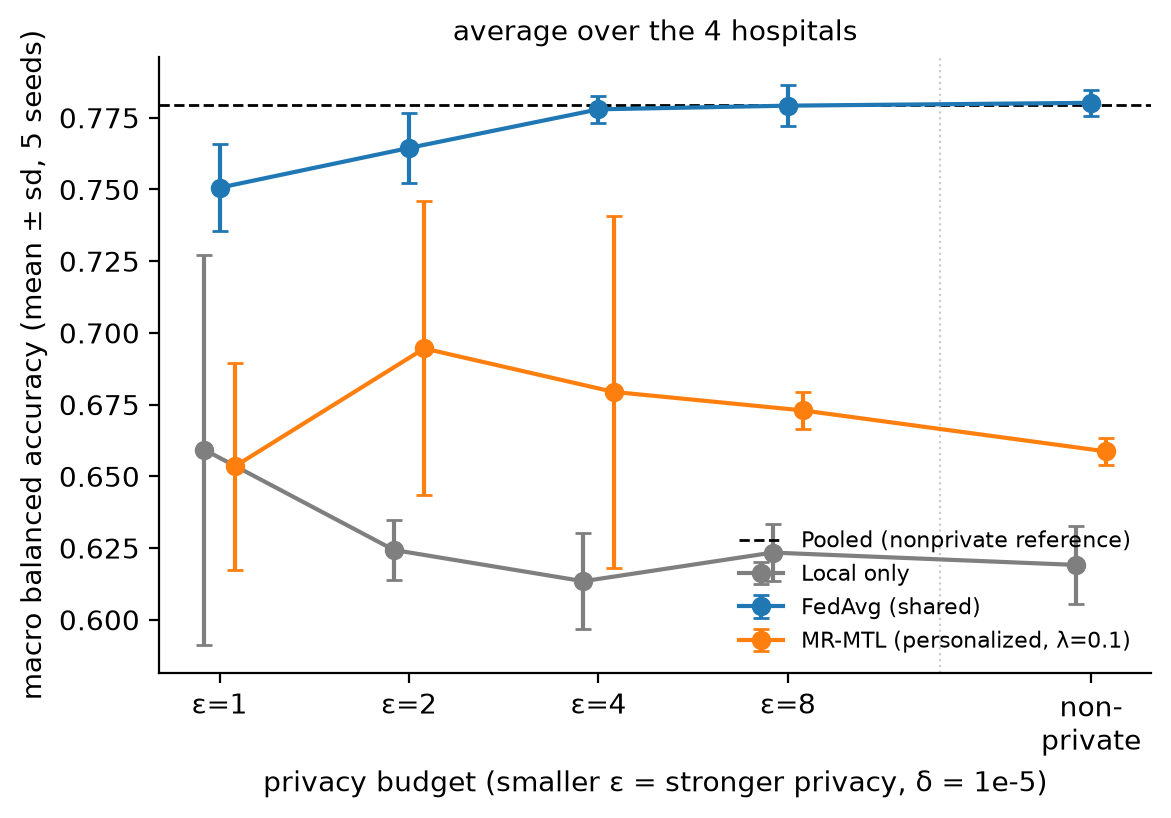

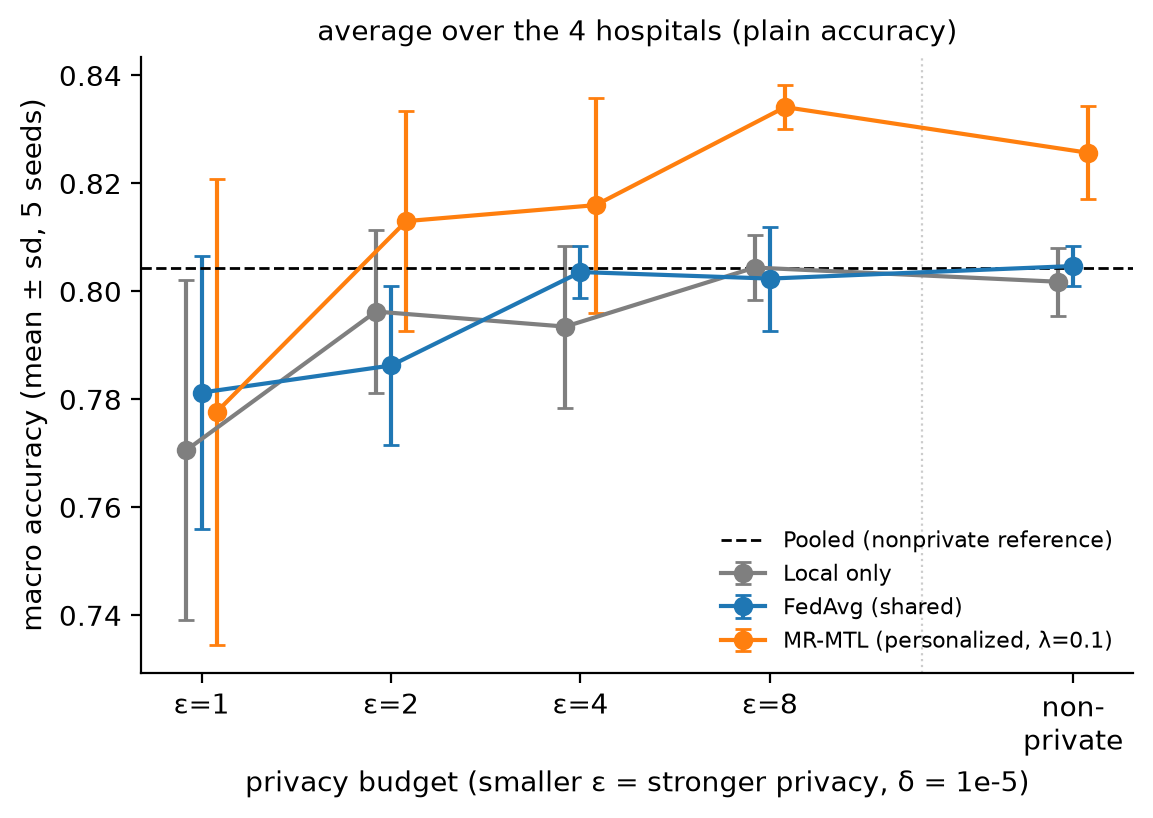

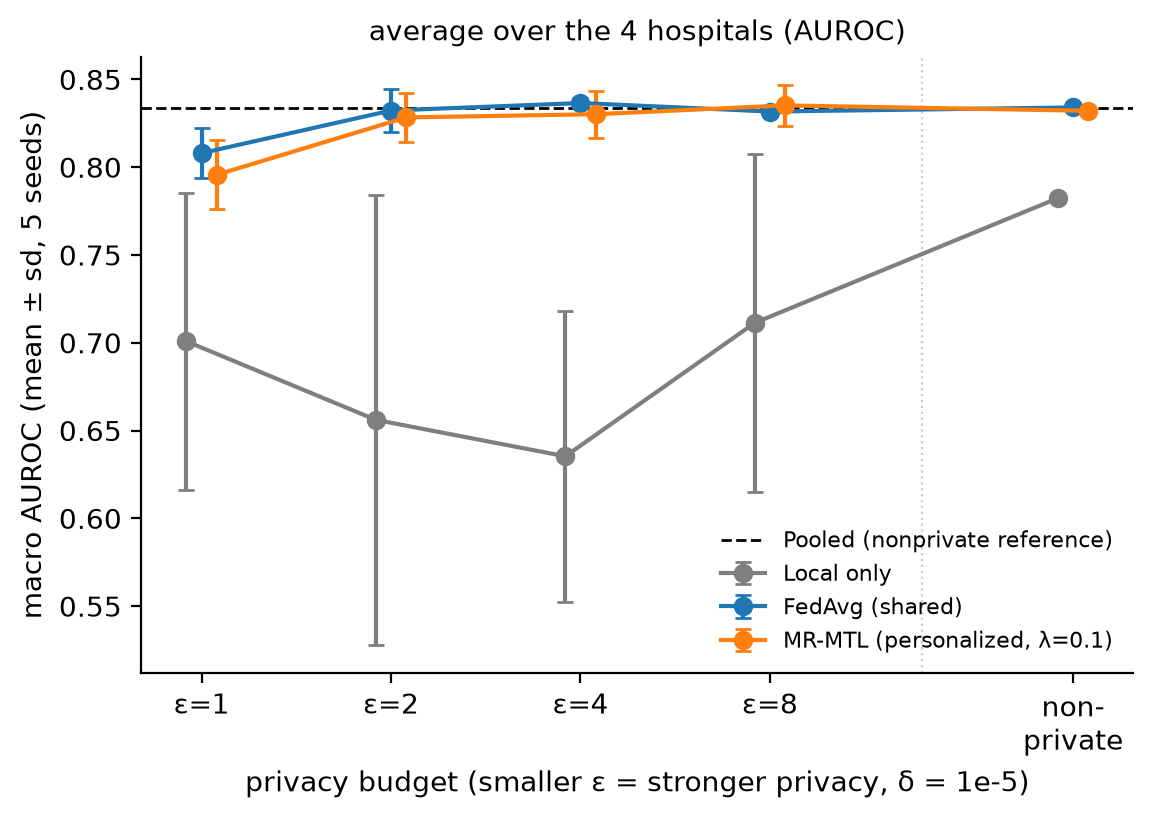

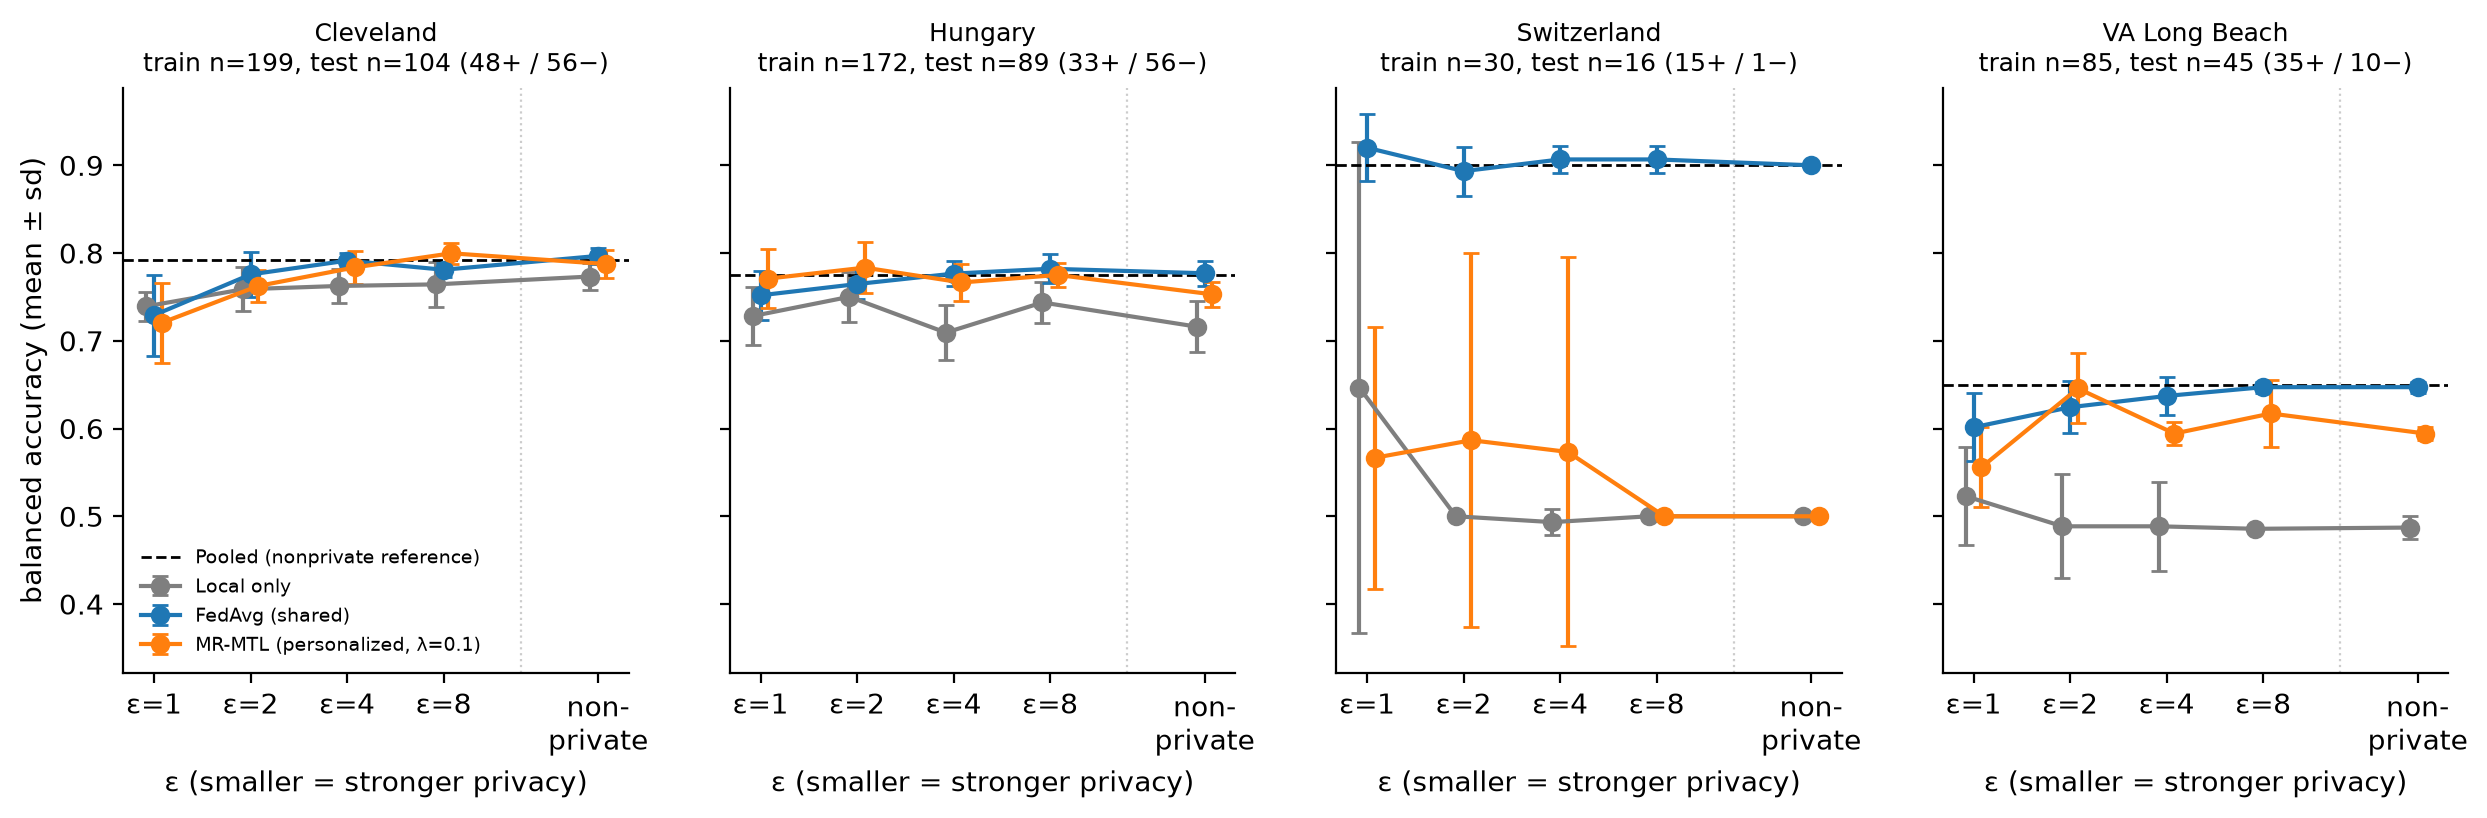

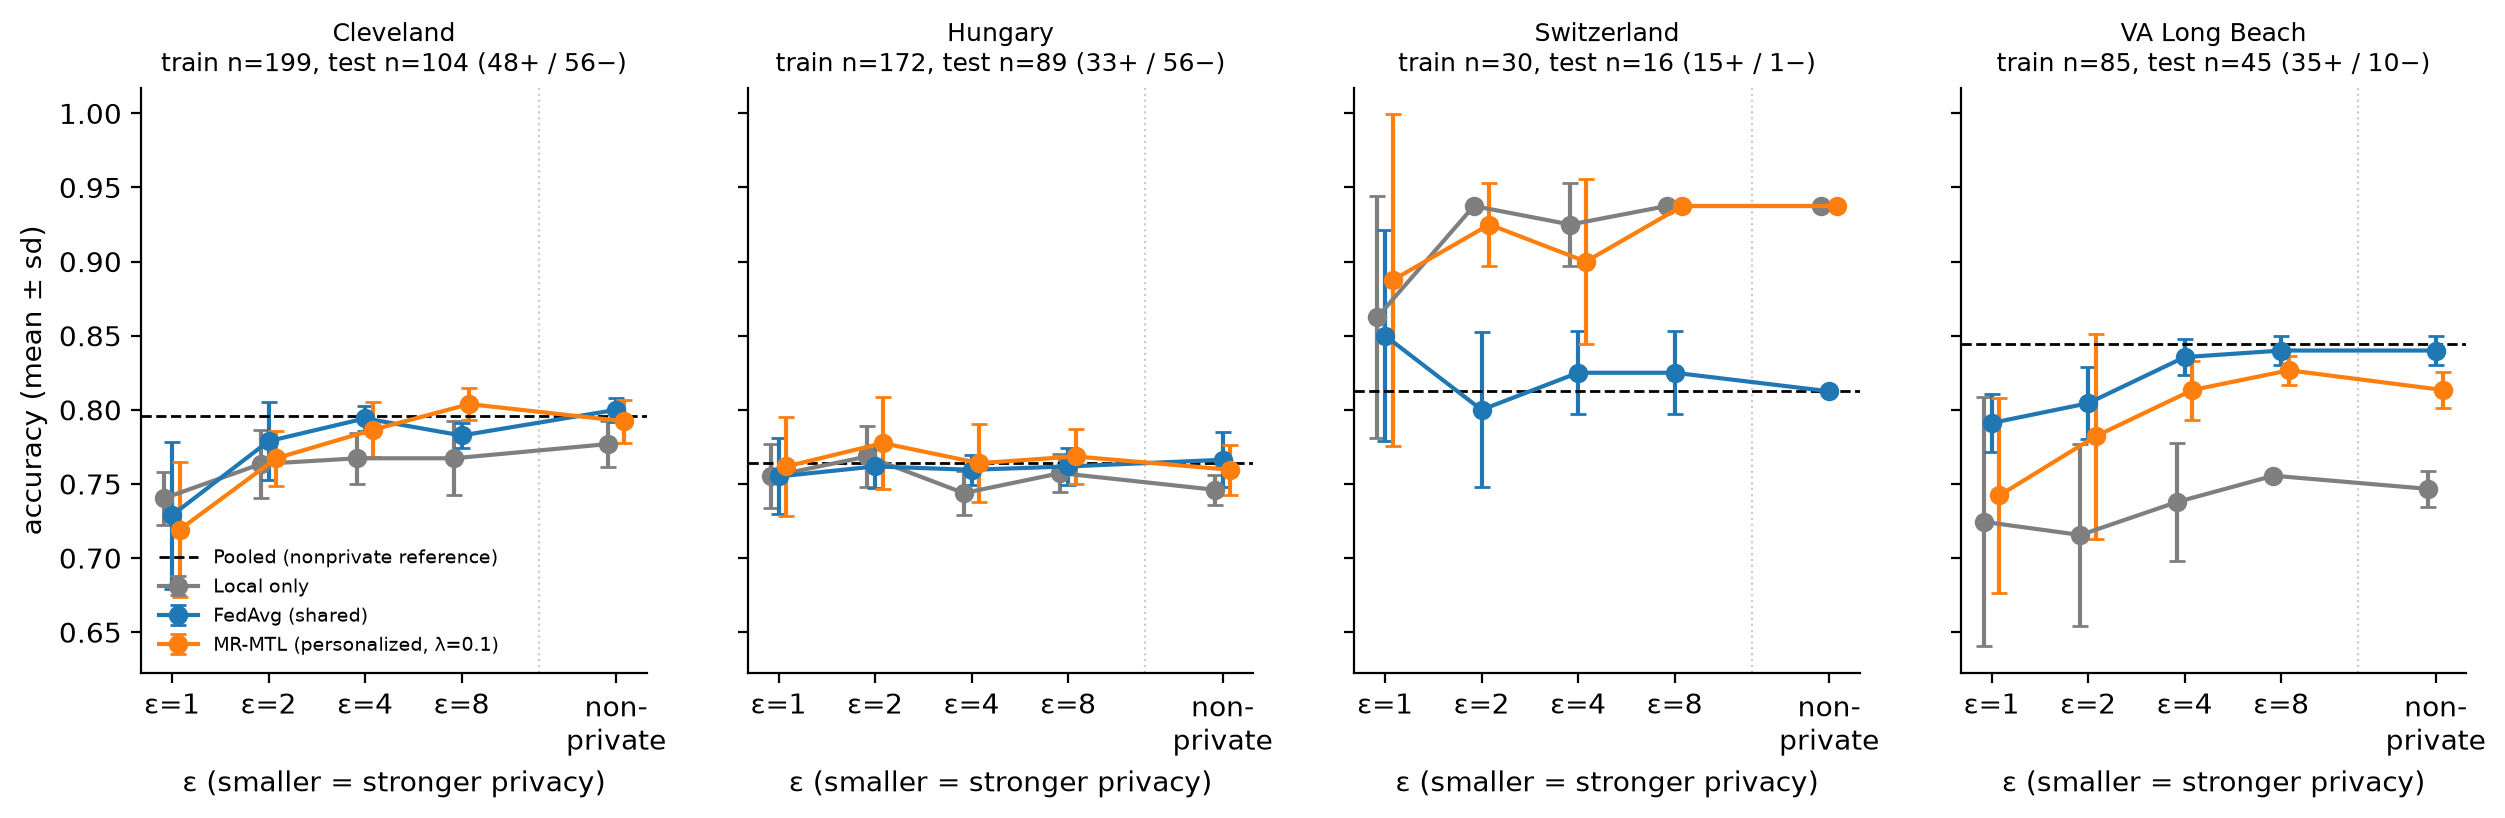

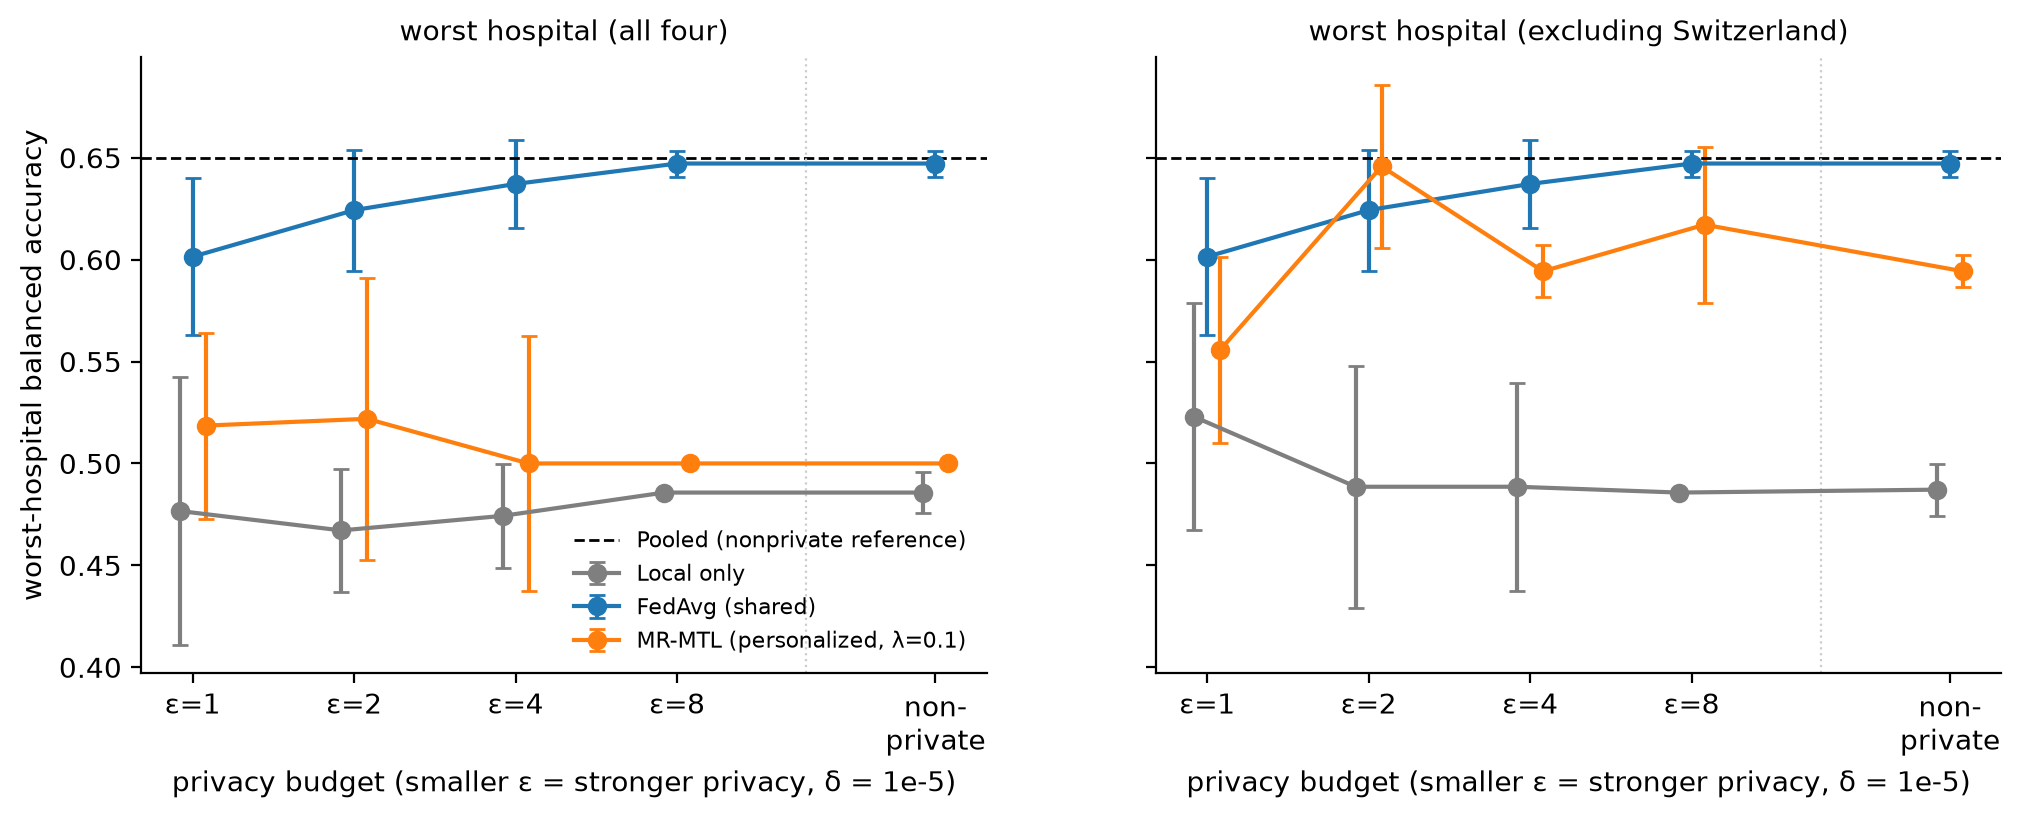

In [7]:
for f in ["balanced_accuracy_vs_privacy", "accuracy_vs_privacy", "auroc_vs_privacy",
          "hospitals_balanced_accuracy", "hospitals_accuracy", "worst_hospital"]:
    display(Image(filename=str(FIGURES / f"{f}.png")))

In [8]:
# how each hospital did
hc = hosp[hosp.group == "core"]
for m in ["balanced_accuracy", "accuracy", "auroc", "sensitivity", "specificity"]:
    print(m); display(hc.pivot(index="setting", columns="hospital_name", values=f"{m}_mean").round(3))

balanced_accuracy


hospital_name,Cleveland,Hungary,Switzerland,VA Long Beach
setting,,,,
fedavg | clip_only,0.801,0.789,0.900,0.650
fedavg | eps=1,0.729,0.752,0.920,0.601
fedavg | eps=2,0.776,0.765,0.893,0.624
fedavg | eps=4,0.791,0.777,0.907,0.637
fedavg | eps=8,0.781,0.782,0.907,0.647
fedavg | nonprivate,0.797,0.777,0.900,0.647
local | eps=1,0.739,0.728,0.647,0.523
local | eps=2,0.759,0.750,0.500,0.489
local | eps=4,0.762,0.709,0.493,0.489


accuracy


hospital_name,Cleveland,Hungary,Switzerland,VA Long Beach
setting,,,,
fedavg | clip_only,0.804,0.769,0.812,0.844
fedavg | eps=1,0.729,0.755,0.850,0.791
fedavg | eps=2,0.779,0.762,0.800,0.804
fedavg | eps=4,0.794,0.760,0.825,0.836
fedavg | eps=8,0.783,0.762,0.825,0.840
fedavg | nonprivate,0.800,0.766,0.812,0.840
local | eps=1,0.740,0.755,0.862,0.724
local | eps=2,0.763,0.769,0.938,0.716
local | eps=4,0.767,0.744,0.925,0.738


auroc


hospital_name,Cleveland,Hungary,Switzerland,VA Long Beach
setting,,,,
fedavg | clip_only,0.824,0.858,0.933,0.717
fedavg | eps=1,0.798,0.838,0.907,0.689
fedavg | eps=2,0.818,0.855,0.920,0.736
fedavg | eps=4,0.824,0.859,0.933,0.730
fedavg | eps=8,0.821,0.857,0.933,0.715
fedavg | nonprivate,0.820,0.862,0.933,0.721
local | eps=1,0.784,0.833,0.640,0.546
local | eps=2,0.817,0.841,0.453,0.513
local | eps=4,0.828,0.844,0.293,0.575


sensitivity


hospital_name,Cleveland,Hungary,Switzerland,VA Long Beach
setting,,,,
fedavg | clip_only,0.771,0.867,0.800,1.000
fedavg | eps=1,0.733,0.739,0.840,0.943
fedavg | eps=2,0.733,0.776,0.787,0.949
fedavg | eps=4,0.754,0.842,0.813,0.994
fedavg | eps=8,0.758,0.861,0.813,0.994
fedavg | nonprivate,0.754,0.818,0.800,0.994
local | eps=1,0.725,0.624,0.893,0.886
local | eps=2,0.696,0.679,1.000,0.897
local | eps=4,0.700,0.576,0.987,0.937


specificity


hospital_name,Cleveland,Hungary,Switzerland,VA Long Beach
setting,,,,
fedavg | clip_only,0.832,0.711,1.0,0.30
fedavg | eps=1,0.725,0.764,1.0,0.26
fedavg | eps=2,0.818,0.754,1.0,0.30
fedavg | eps=4,0.829,0.711,1.0,0.28
fedavg | eps=8,0.804,0.704,1.0,0.30
fedavg | nonprivate,0.839,0.736,1.0,0.30
local | eps=1,0.754,0.832,0.4,0.16
local | eps=2,0.821,0.821,0.0,0.08
local | eps=4,0.825,0.843,0.0,0.04


In [9]:
# privacy ledger. every hospital ends at or under its eps target
ptab

,epsilon_target,hospital_id,hospital_name,n_train_slots,sample_rate,expected_batch,clip_norm,noise_multiplier,steps,epsilon_realized_max,delta,n_runs,mean_actual_batch,expected_epochs
0,1.0,0,Cleveland,199,0.080402,16.0,1.0,5.312500,250.0,0.998385,0.00001,15,15.961333,20.100503
1,1.0,1,Hungary,172,0.093023,16.0,1.0,6.132812,250.0,0.994764,0.00001,15,16.000000,23.255814
2,1.0,2,Switzerland,30,0.533333,16.0,1.0,34.375000,250.0,0.993666,0.00001,15,15.995733,133.333333
3,1.0,3,VA Long Beach,85,0.188235,16.0,1.0,12.187500,250.0,0.997616,0.00001,15,16.102933,47.058824
4,2.0,0,Cleveland,199,0.080402,16.0,1.0,2.929688,250.0,1.999116,0.00001,15,15.973600,20.100503
5,2.0,1,Hungary,172,0.093023,16.0,1.0,3.349609,250.0,1.996538,0.00001,15,15.967200,23.255814
6,2.0,2,Switzerland,30,0.533333,16.0,1.0,18.203125,250.0,1.998261,0.00001,15,15.971467,133.333333
7,2.0,3,VA Long Beach,85,0.188235,16.0,1.0,6.542969,250.0,1.995746,0.00001,15,15.951200,47.058824
8,4.0,0,Cleveland,199,0.080402,16.0,1.0,1.723633,250.0,3.990673,0.00001,15,15.964267,20.100503
9,4.0,1,Hungary,172,0.093023,16.0,1.0,1.933594,250.0,3.998337,0.00001,15,15.992800,23.255814


In [10]:
# what privacy cost each hospital, in points. negative means private actually did better
display(cost.pivot_table(index=["method", "privacy"], columns="hospital_name", values="cost_balanced_accuracy_pp").round(1))
cost.pivot_table(index=["method", "privacy"], columns="hospital_name", values="cost_accuracy_pp").round(1)

hospital_name   Cleveland  Hungary  Switzerland  VA Long Beach
method privacy                                                
fedavg eps=1          6.8      2.5         -2.0            4.6
       eps=2          2.1      1.2          0.7            2.3
       eps=4          0.5      0.0         -0.7            1.0
       eps=8          1.6     -0.5         -0.7            0.0
local  eps=1          3.4     -1.2        -14.7           -3.6
       eps=2          1.5     -3.4          0.0           -0.1
       eps=4          1.1      0.7          0.7           -0.1
       eps=8          0.9     -2.8          0.0            0.1
mrmtl  eps=1          6.7     -1.8         -6.7            3.9
       eps=2          2.5     -3.0         -8.7           -5.1
       eps=4          0.4     -1.4         -7.3            0.0
       eps=8         -1.2     -2.2          0.0           -2.3

hospital_name   Cleveland  Hungary  Switzerland  VA Long Beach
method privacy                                                
fedavg eps=1          7.1      1.1         -3.7            4.9
       eps=2          2.1      0.4          1.2            3.6
       eps=4          0.6      0.7         -1.2            0.4
       eps=8          1.7      0.4         -1.2            0.0
local  eps=1          3.7     -0.9          7.5            2.2
       eps=2          1.3     -2.2          0.0            3.1
       eps=4          1.0      0.2          1.2            0.9
       eps=8          1.0     -1.1          0.0           -0.9
mrmtl  eps=1          7.3     -0.2          5.0            7.1
       eps=2          2.5     -1.8          1.2            3.1
       eps=4          0.6     -0.4          3.7            0.0
       eps=8         -1.2     -0.9          0.0           -1.3

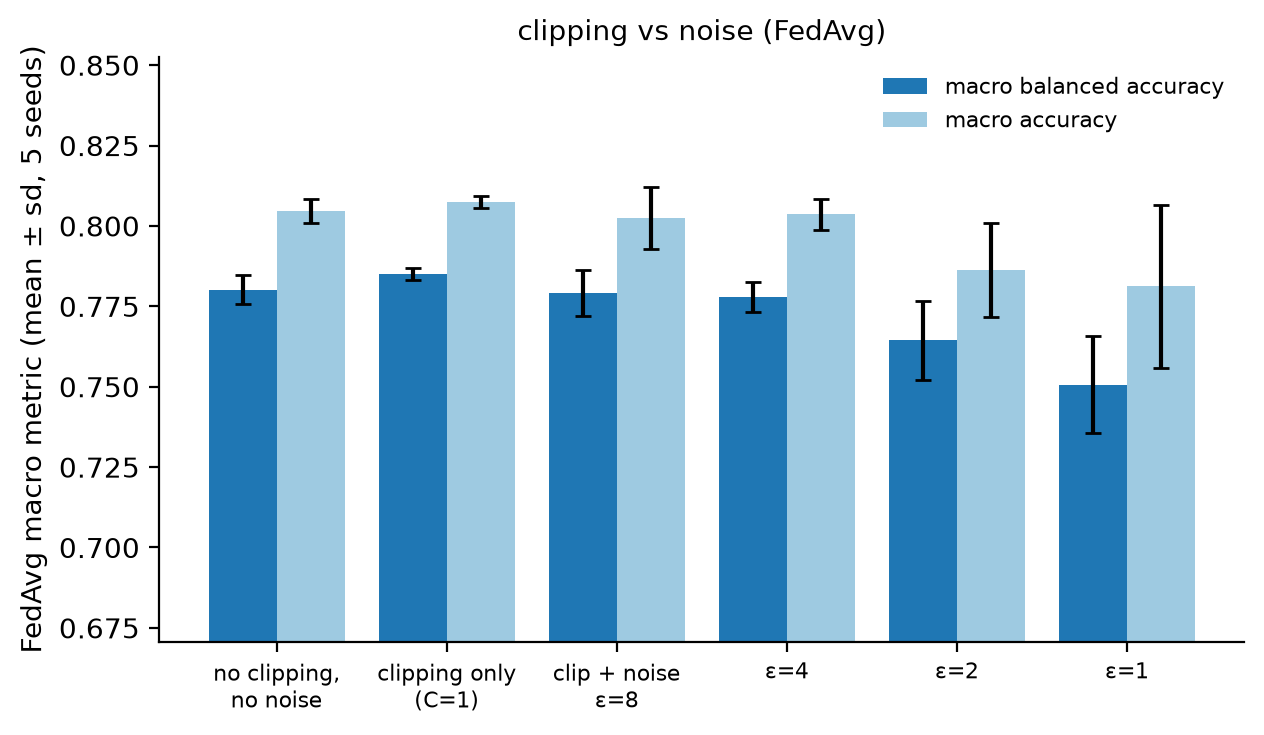

,hospitals,a,b,diff_pp,lo_pp,hi_pp,share_draws_a_better
27,all,fedavg | nonprivate,fedavg | clip_only,-0.48,-1.62,0.43,0.17
28,all,fedavg | clip_only,fedavg | eps=1,3.44,0.67,6.31,1.00
56,excl_switzerland,fedavg | nonprivate,fedavg | clip_only,-0.65,-2.25,0.59,0.18
57,excl_switzerland,fedavg | clip_only,fedavg | eps=1,5.26,1.87,8.50,1.00


In [11]:
# clipping alone doesn't hurt, the noise does
display(Image(filename=str(FIGURES / "clipping_vs_noise.png")))
con[con.a.str.contains("clip_only") | con.b.str.contains("clip_only")].round(2)

privacy,eps=2,eps=8,nonprivate
lambda,,,
0.00,0.624,0.632,0.621
0.01,0.630,0.621,0.630
0.10,0.695,0.673,0.659
1.00,0.709,0.785,0.785


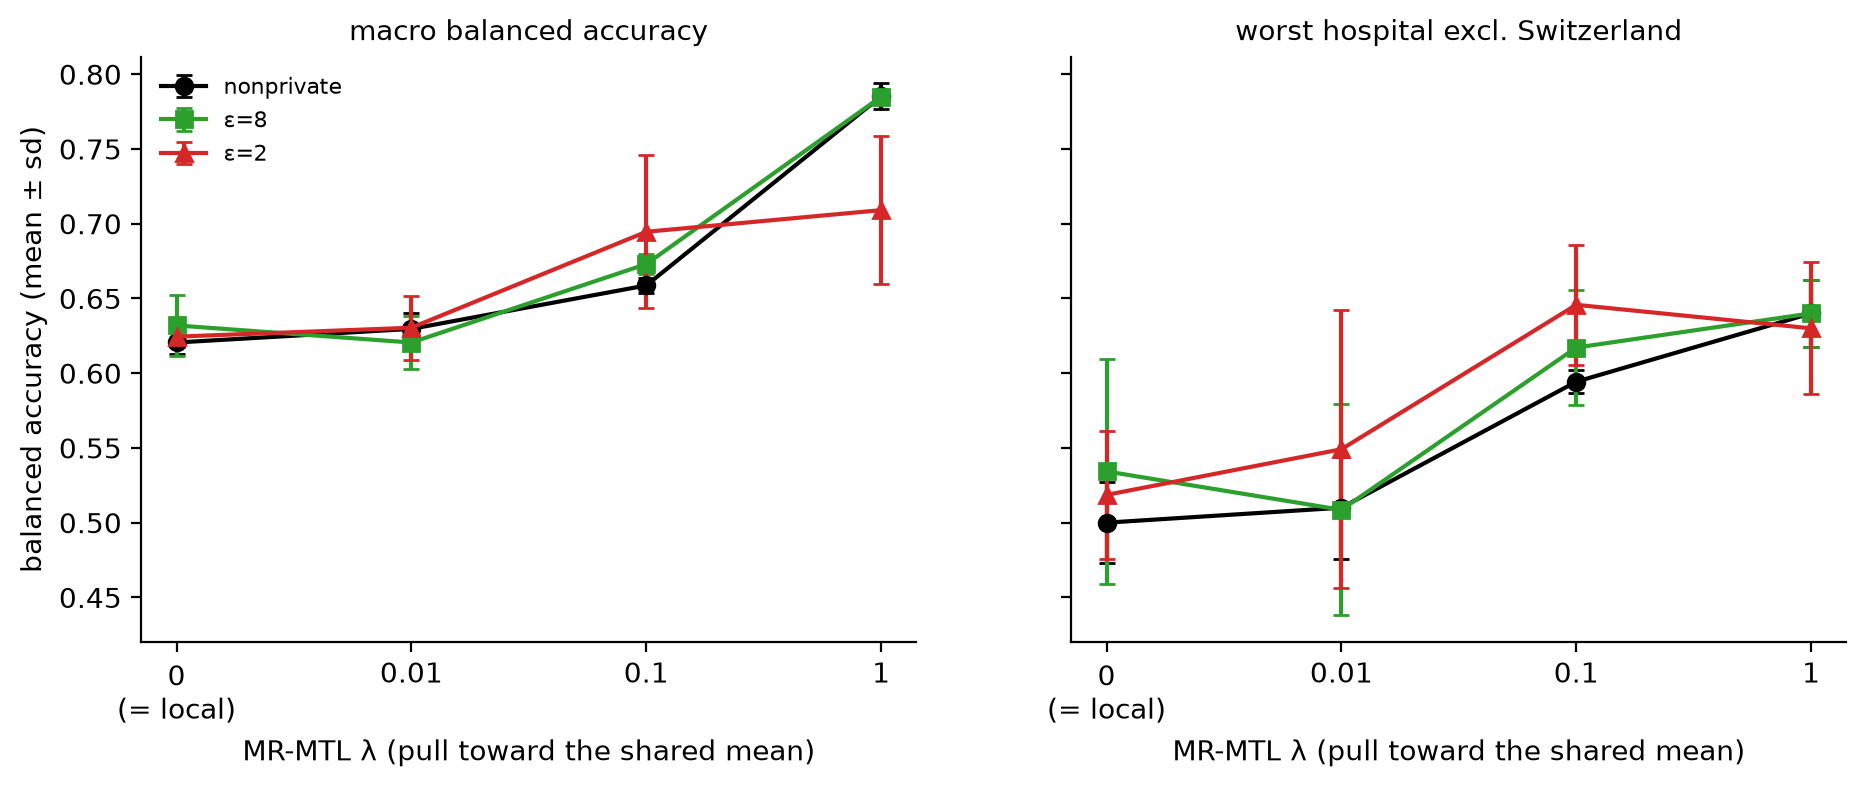

In [12]:
# lambda sweep. 0 is the same as local, bigger gets closer to fedavg
lam = s[(s.method == "mrmtl") & s.group.isin(["core", "lambda_sweep"]) & (s.weighting == "size") & (s.chol_policy == "keep_zero")
        & (s.train_fraction_site == 1.0) & s.privacy.isin(["nonprivate", "eps=8", "eps=2"])]
display(lam.pivot(index="lambda", columns="privacy", values="macro_balanced_accuracy_mean").round(3))
display(Image(filename=str(FIGURES / "lambda_sweep.png")))

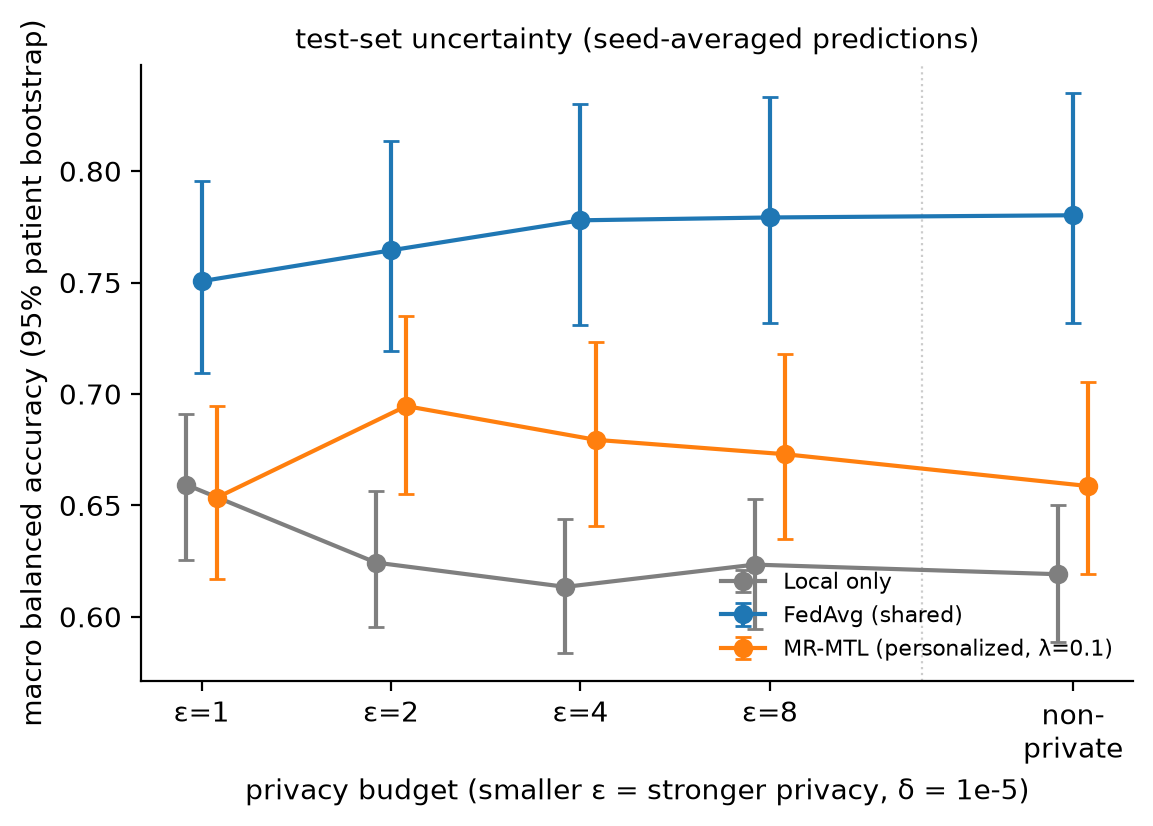

,setting,point,lo,hi,hospitals
0,pooled | nonprivate,0.779,0.730,0.833,all
1,local | nonprivate,0.619,0.589,0.650,all
2,local | eps=1,0.659,0.626,0.691,all
3,local | eps=2,0.624,0.595,0.656,all
4,local | eps=4,0.613,0.584,0.644,all
5,local | eps=8,0.623,0.595,0.653,all
6,fedavg | nonprivate,0.780,0.732,0.835,all
7,fedavg | eps=1,0.751,0.709,0.796,all
8,fedavg | eps=2,0.764,0.719,0.814,all
9,fedavg | eps=4,0.778,0.731,0.830,all


In [13]:
# how much our scores could move with different test patients (95% intervals)
display(Image(filename=str(FIGURES / "bootstrap_intervals.png")))
ci.round(3)

In [14]:
# head to head differences, a minus b
con.round(2)

,hospitals,a,b,diff_pp,lo_pp,hi_pp,share_draws_a_better
0,all,fedavg | nonprivate,local | nonprivate,16.11,11.69,20.73,1.00
1,all,mrmtl | nonprivate | lam=0.1,fedavg | nonprivate,-12.15,-15.70,-8.84,0.00
2,all,mrmtl | nonprivate | lam=0.1,local | nonprivate,3.96,1.11,7.55,1.00
3,all,fedavg | eps=1,local | eps=1,9.14,5.01,13.46,1.00
4,all,mrmtl | eps=1 | lam=0.1,fedavg | eps=1,-9.72,-12.28,-7.19,0.00
5,all,mrmtl | eps=1 | lam=0.1,local | eps=1,-0.58,-4.03,3.43,0.39
6,all,fedavg | eps=2,local | eps=2,14.01,10.21,17.94,1.00
7,all,mrmtl | eps=2 | lam=0.1,fedavg | eps=2,-6.99,-9.15,-4.59,0.00
8,all,mrmtl | eps=2 | lam=0.1,local | eps=2,7.02,4.16,10.03,1.00
9,all,fedavg | eps=4,local | eps=4,16.45,12.19,20.95,1.00


In [15]:
# our extra checks: equal weights, chol as missing, flamby's scaling, and a smaller cleveland
s[~s.group.isin(["core"])][["group", "setting", "macro_balanced_accuracy_mean", "macro_balanced_accuracy_std",
    "worst_balanced_accuracy_mean", "worst_balanced_accuracy_excl_switzerland_mean", "macro_accuracy_mean"]].sort_values(["group", "setting"]).round(3)

,group,setting,macro_balanced_accuracy_mean,macro_balanced_accuracy_std,worst_balanced_accuracy_mean,worst_balanced_accuracy_excl_switzerland_mean,macro_accuracy_mean
3,chol_sensitivity,fedavg | eps=2 | chol_missing,0.760,0.058,0.620,0.640,0.819
10,chol_sensitivity,fedavg | nonprivate | chol_missing,0.785,0.005,0.650,0.650,0.818
17,chol_sensitivity,local | eps=2 | chol_missing,0.629,0.036,0.453,0.540,0.789
23,chol_sensitivity,local | nonprivate | chol_missing,0.625,0.011,0.474,0.476,0.795
31,chol_sensitivity,mrmtl | eps=2 | lam=0.1 | chol_missing,0.694,0.045,0.514,0.577,0.801
44,chol_sensitivity,mrmtl | nonprivate | lam=0.1 | chol_missing,0.657,0.007,0.500,0.597,0.825
6,equal_weights,fedavg | eps=2 | equal_w,0.677,0.084,0.538,0.606,0.773
13,equal_weights,fedavg | nonprivate | equal_w,0.773,0.002,0.550,0.550,0.820
34,equal_weights,mrmtl | eps=2 | lam=0.1 | equal_w,0.657,0.053,0.510,0.557,0.794
47,equal_weights,mrmtl | nonprivate | lam=0.1 | equal_w,0.665,0.004,0.500,0.600,0.830


,setting,n_train,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,auroc_mean
8,fedavg | eps=2,199,0.776,0.026,0.779,0.818
16,fedavg | eps=2 | cleveland_frac=0.25,50,0.738,0.021,0.735,0.806
20,fedavg | eps=2 | cleveland_frac=0.5,100,0.751,0.033,0.750,0.804
36,fedavg | nonprivate,199,0.797,0.009,0.800,0.820
44,fedavg | nonprivate | cleveland_frac=0.25,50,0.757,0.019,0.760,0.823
48,fedavg | nonprivate | cleveland_frac=0.5,100,0.784,0.000,0.788,0.824
64,local | eps=2,199,0.759,0.025,0.763,0.817
72,local | eps=2 | cleveland_frac=0.25,50,0.634,0.081,0.635,0.710
76,local | eps=2 | cleveland_frac=0.5,100,0.722,0.052,0.725,0.788
88,local | nonprivate,199,0.773,0.016,0.777,0.821


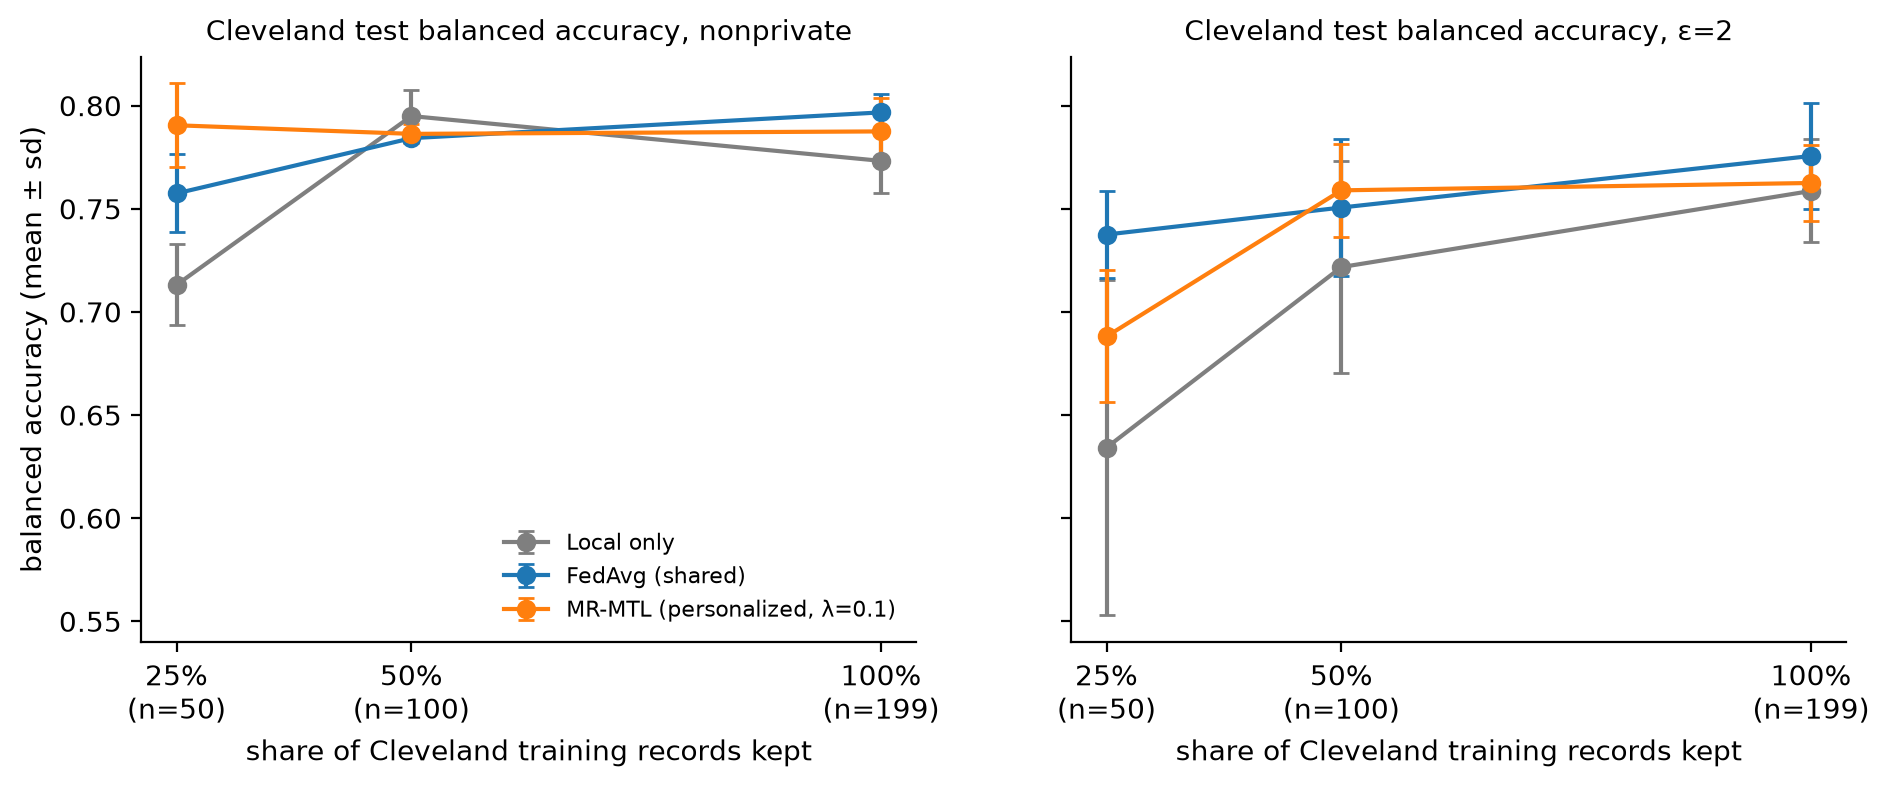

In [16]:
# just cleveland, as we shrink its training set
cl = hosp[(hosp.hospital_name == "Cleveland") & (hosp.group.isin(["size_analysis"])
          | ((hosp.group == "core") & hosp.privacy.isin(["nonprivate", "eps=2"]) & hosp.method.isin(["local", "fedavg", "mrmtl"])))]
display(cl[["setting", "n_train", "balanced_accuracy_mean", "balanced_accuracy_std", "accuracy_mean", "auroc_mean"]].sort_values("setting").round(3))
display(Image(filename=str(FIGURES / "cleveland_size.png")))

In [17]:
# markdown tables for our report, saved to results/tables.md
ORDER = ["pooled | nonprivate",
         "local | nonprivate", "local | eps=8", "local | eps=4", "local | eps=2", "local | eps=1",
         "fedavg | nonprivate", "fedavg | clip_only", "fedavg | eps=8", "fedavg | eps=4", "fedavg | eps=2", "fedavg | eps=1",
         "mrmtl | nonprivate | lam=0.1", "mrmtl | eps=8 | lam=0.1", "mrmtl | eps=4 | lam=0.1", "mrmtl | eps=2 | lam=0.1", "mrmtl | eps=1 | lam=0.1"]
pm = lambda m, d: [f"{a:.3f} ± {b:.3f}" for a, b in zip(m, d)]


def md(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    lines += ["| " + " | ".join(str(r[c]).replace(" | ", ", ") for c in cols) + " |" for _, r in df.iterrows()]
    return "\n".join(lines)


parts = []
rows = []
for cid in CENTER_IDS:
    name = CENTERS[cid][0]
    tr, te = labels.loc[(cid, name, "train")], labels.loc[(cid, name, "test")]
    rows.append({"hospital": name, "source rows": counts.loc[(cid, name), "source"], "retained": counts.loc[(cid, name), "retained"],
                 "removed": counts.loc[(cid, name), "removed"], "train (pos/neg)": f"{tr.total:.0f} ({tr.positive:.0f}/{tr.negative:.0f})",
                 "test (pos/neg)": f"{te.total:.0f} ({te.positive:.0f}/{te.negative:.0f})", "train prevalence": f"{tr.prevalence:.2f}",
                 "chol = 0 (retained)": unusual.loc[name, "chol_zero_retained"]})
parts.append("### data by hospital\n\n" + md(pd.DataFrame(rows)))

c = s[s.group == "core"].set_index("setting").loc[ORDER].reset_index()
parts.append("### main results (mean ± sd over 5 seeds, BA is balanced accuracy, CH is Switzerland)\n\n" + md(pd.DataFrame({
    "setting": c.setting, "macro BA": pm(c.macro_balanced_accuracy_mean, c.macro_balanced_accuracy_std),
    "worst-hospital BA": pm(c.worst_balanced_accuracy_mean, c.worst_balanced_accuracy_std), "worst hospital": c.worst_hospital_mode,
    "worst BA excl. CH": pm(c.worst_balanced_accuracy_excl_switzerland_mean, c.worst_balanced_accuracy_excl_switzerland_std),
    "macro accuracy": pm(c.macro_accuracy_mean, c.macro_accuracy_std), "macro AUROC": pm(c.macro_auroc_mean, c.macro_auroc_std),
    "pooled test acc.": pm(c.pooled_test_accuracy_mean, c.pooled_test_accuracy_std)})))

for metric, label in [("balanced_accuracy", "balanced accuracy"), ("accuracy", "accuracy"), ("auroc", "AUROC"),
                                             ("sensitivity", "sensitivity"), ("specificity", "specificity")]:
    pv = hc.pivot(index="setting", columns="hospital_name", values=f"{metric}_mean").loc[ORDER, HOSP]
    sd = hc.pivot(index="setting", columns="hospital_name", values=f"{metric}_std").loc[ORDER, HOSP]
    tt = pd.DataFrame({"setting": pv.index, **{h: pm(pv[h], sd[h]) for h in HOSP}})
    parts.append(f"### per-hospital {label} (mean ± sd, 5 seeds)\n\n" + md(tt))

cc = cost.copy()
cc["privacy"] = pd.Categorical(cc.privacy, ["eps=8", "eps=4", "eps=2", "eps=1"])
for col, label in [("cost_balanced_accuracy_pp", "balanced accuracy"), ("cost_accuracy_pp", "accuracy")]:
    parts.append(f"### what privacy cost in {label} (points lost vs nonprivate, negative means private did better)\n\n"
                 + md(cc.pivot_table(index=["method", "privacy"], columns="hospital_name", values=col, observed=True)[HOSP].round(1).reset_index()))

pt = ptab[["epsilon_target", "hospital_name", "n_train_slots", "sample_rate", "expected_batch", "mean_actual_batch", "expected_epochs",
           "clip_norm", "noise_multiplier", "steps", "epsilon_realized_max", "delta", "n_runs"]].copy()
for col, d in [("sample_rate", 4), ("mean_actual_batch", 2), ("expected_epochs", 1), ("noise_multiplier", 3), ("epsilon_realized_max", 4)]:
    pt[col] = pt[col].round(d)
pt["delta"], pt["steps"] = pt["delta"].map(lambda x: f"{x:g}"), pt["steps"].astype(int)
parts.append("### privacy ledger for every private run\n\n" + md(pt))

b = ci.assign(ci95=ci.apply(lambda r: f"{r.point:.3f} [{r.lo:.3f}, {r.hi:.3f}]", axis=1))
bp = b.pivot(index="setting", columns="hospitals", values="ci95")
parts.append("### how sure we are about the main results (95% intervals from resampling test patients)\n\n"
             + md(bp.loc[[o for o in ORDER if o in bp.index]].reset_index()))

k = con.assign(**{"difference (pp) [95% CI]": con.apply(lambda r: f"{r.diff_pp:+.1f} [{r.lo_pp:+.1f}, {r.hi_pp:+.1f}]", axis=1)})
k["share_draws_a_better"] = k["share_draws_a_better"].round(2)
parts.append("### head to head differences in balanced accuracy (a minus b, with 95% intervals)\n\n"
             + md(k[["hospitals", "a", "b", "difference (pp) [95% CI]", "share_draws_a_better"]]))

keep = s[s.group.isin(["lambda_sweep", "equal_weights", "chol_sensitivity", "flamby_parity", "size_analysis"])
         | ((s.group == "core") & (s.method == "mrmtl") & s.privacy.isin(["nonprivate", "eps=2", "eps=8"]))].sort_values(["group", "setting"])
parts.append("### extra checks (mean ± sd, 5 seeds)\n\n" + md(pd.DataFrame({
    "group": keep.group, "setting": keep.setting, "macro BA": pm(keep.macro_balanced_accuracy_mean, keep.macro_balanced_accuracy_std),
    "worst BA": pm(keep.worst_balanced_accuracy_mean, keep.worst_balanced_accuracy_std),
    "worst BA excl. CH": pm(keep.worst_balanced_accuracy_excl_switzerland_mean, keep.worst_balanced_accuracy_excl_switzerland_std),
    "macro accuracy": pm(keep.macro_accuracy_mean, keep.macro_accuracy_std), "macro AUROC": pm(keep.macro_auroc_mean, keep.macro_auroc_std)})))

cl2 = cl.sort_values("setting")
parts.append("### shrinking Cleveland's training set (other hospitals unchanged)\n\n" + md(pd.DataFrame({
    "setting": cl2.setting, "cleveland n_train": cl2.n_train, "cleveland BA": pm(cl2.balanced_accuracy_mean, cl2.balanced_accuracy_std),
    "cleveland accuracy": pm(cl2.accuracy_mean, cl2.accuracy_std), "cleveland AUROC": pm(cl2.auroc_mean, cl2.auroc_std)})))

tables_md = "\n\n".join(parts) + "\n"
(OUT / "tables.md").write_text(tables_md, encoding="utf-8")
print("saved our report tables to results/tables.md")

saved our report tables to results/tables.md
